# Muon variants without NorMuon / Muon+: loss vs wall-clock, bpb vs steps / LR, time-to-target (d8, d12)

Parses the nanochat training logs from the `plain_*` sweep (`logs/slurm/sweep/plain_d*.out`), where **NorMuon variance reduction and Muon+ renormalization are both OFF** (`--no-normuon --no-muonplus`) and only MuonEq / Muon$^2$ vary. Depths with no finished runs yet are skipped, so this can be re-run as the sweep progresses.

- **Wall-clock** = nanochat's own `total time` counter: pure training step time, excluding the first 10 steps, evals and compile/startup.
- **Wall-clock / steps plots**: per depth, each variant at its best LR (lowest final val bpb among finished runs). Set `LR_MODE` to a number to pin one LR instead.
- **bpb vs LR plot**: final val bpb against `--matrix-lr`, one line per variant, one panel per depth.
- **Time-to-target table**: target = the worst final value among the compared variants (per depth); steps and wall-clock to first reach it, plus speedup.
- **Outputs**: every figure is saved (PNG + PDF) to `<repo>/results/figures/` and every table (CSV) to `<repo>/results/tables/`. File names carry `TAG_PREFIX`, so different sweeps don't overwrite each other.

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DEPTHS = [8, 12]
TAG_PREFIX = "plain"    # run-tag prefix set in sweep.sbatch (logs are <prefix>_d<depth>_<variant>_lr<lr>-<jobid>.out)
LR_MODE = "best"        # "best" = best final val bpb per (depth, variant); or a number like 0.02 to pin one LR for all
SHOW_ALL_LRS = False    # in the wall-clock plots, also draw the non-selected LRs as faint lines
LOSS_ZOOM, BPB_ZOOM = 1.0, 0.25   # y-range above the best final value in the wall-clock plots

LABELS = {
    "eq":    "MuonEq",
    "eq_m2": "MuonEq + Muon$^2$",
    "m2":    "Muon$^2$",
    "base":  "Muon (no EQ, no Muon$^2$)",
}
COLORS = {"eq": "tab:blue", "eq_m2": "tab:red", "m2": "tab:green", "base": "tab:gray"}

# --- output directories: <repo root>/results/{figures,tables}; the notebook lives in <repo root>/notebooks/
def find_repo_root():
    cwd = Path.cwd().resolve()
    for p in [cwd, *cwd.parents]:
        if (p / ".git").exists():
            return p
    return cwd.parent if cwd.name == "notebooks" else cwd

ROOT = find_repo_root()
FIG_DIR, TAB_DIR = ROOT / "results" / "figures", ROOT / "results" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)
print("repo root:", ROOT)

def savefig(fig, name):
    """Save a figure as PNG and PDF in results/figures (call before plt.show())."""
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"{TAG_PREFIX}_{name}.{ext}", dpi=200, bbox_inches="tight")

def savetable(df, name, index=True):
    """Save a table as CSV in results/tables."""
    df.to_csv(TAB_DIR / f"{TAG_PREFIX}_{name}.csv", index=index)

repo root: /home/simon/work/courses/dsa4k/optimizer-comparison


In [2]:
FILE_RE  = re.compile(rf"{re.escape(TAG_PREFIX)}_d(\d+)_(eq_m2|eq|m2|base)_lr([0-9.eE+-]+?)-(\d+)\.out$")
STEP_RE  = re.compile(r"^step (\d+)/(\d+) .*?\| loss: ([0-9.]+) .*?\| dt: ([0-9.]+)ms .*?total time: ([0-9.]+)m", re.M)
VAL_RE   = re.compile(r"^Step (\d+) \| Validation bpb: ([0-9.]+)", re.M)

# Find every logs/slurm/sweep dir at or above the cwd (the scripts may have been launched from a subdir like jobs/)
log_dirs = [p / "logs" / "slurm" / "sweep" for p in [Path.cwd(), *Path.cwd().parents]]
log_dirs = [d for d in log_dirs if d.is_dir()]
print("log dirs:", [str(d) for d in log_dirs])

runs = {}   # (depth, variant, lr) -> dict; if a tag has several logs keep the one with the most steps
for d in log_dirs:
    for path in d.glob("*.out"):
        m = FILE_RE.search(path.name)
        if not m or int(m.group(1)) not in DEPTHS:
            continue
        text = path.read_text(errors="replace")
        steps = STEP_RE.findall(text)
        if not steps:
            continue
        train = pd.DataFrame(steps, columns=["step", "n_iters", "loss", "dt_ms", "time_min"]).astype(float)
        val = pd.DataFrame(VAL_RE.findall(text), columns=["step", "val_bpb"]).astype(float)
        # wall-clock (training time only) at each eval step; the last eval comes after the final train step
        val["time_min"] = np.interp(val["step"], train["step"], train["time_min"])
        n_iters = int(train["n_iters"].iloc[0])
        mb = re.search(r"[Tt]otal batch size[^0-9]*([\d,]+)", text)   # tokens per optimizer step (NaN if the log line isn't found)
        batch_tokens = int(mb.group(1).replace(",", "")) if mb else np.nan
        key = (int(m.group(1)), m.group(2), float(m.group(3)))
        if key not in runs or len(train) > len(runs[key]["train"]):
            runs[key] = dict(train=train, val=val, path=path, n_iters=n_iters, batch_tokens=batch_tokens,
                             finished=len(train) >= n_iters and len(val) > 0)

rows = []
for (depth, v, lr), r in sorted(runs.items()):
    rows.append(dict(depth=depth, variant=v, lr=lr, finished=r["finished"],
                     final_val_bpb=r["val"]["val_bpb"].iloc[-1] if len(r["val"]) else np.nan,
                     final_train_loss=r["train"]["loss"].iloc[-1],
                     train_min=r["train"]["time_min"].iloc[-1],
                     median_ms_per_step=r["train"]["dt_ms"].iloc[10:].median()))
summary = pd.DataFrame(rows)
if len(summary):
    savetable(summary, "all_runs_summary", index=False)
avail = [int(d) for d in sorted(summary[summary.finished].depth.unique())] if len(summary) else []
print("depths with finished runs:", avail)
print("finished runs per depth:", summary[summary.finished].groupby("depth").size().to_dict() if len(summary) else {})
summary

log dirs: ['/home/simon/work/courses/dsa4k/optimizer-comparison/logs/slurm/sweep']
depths with finished runs: [8, 12]
finished runs per depth: {8: 12, 12: 12}


,depth,variant,lr,finished,final_val_bpb,final_train_loss,train_min,median_ms_per_step
0,8,base,0.01,True,0.952284,3.134822,19.88,642.945
1,8,base,0.02,True,0.946592,3.115944,18.84,595.020
2,8,base,0.04,True,0.952156,3.134476,14.52,457.130
3,8,eq,0.01,True,0.947372,3.117911,14.44,454.685
4,8,eq,0.02,True,0.942539,3.103473,14.47,455.375
5,8,eq,0.04,True,0.945419,3.112559,14.50,455.790
6,8,eq_m2,0.01,True,0.953507,3.138367,20.15,645.845
7,8,eq_m2,0.02,True,0.945090,3.111477,16.35,515.130
8,8,eq_m2,0.04,True,0.946482,3.115677,16.06,490.310
9,8,m2,0.01,True,0.954247,3.140973,14.57,457.920


In [3]:
# Pick one LR per (depth, variant)
chosen = {}
for depth in avail:
    for v in LABELS:
        s = summary[(summary.depth == depth) & (summary.variant == v) & summary.finished]
        if s.empty:
            print(f"d{depth}: no finished runs for {v}"); continue
        if LR_MODE == "best":
            chosen[(depth, v)] = s.loc[s.final_val_bpb.idxmin(), "lr"]
        elif float(LR_MODE) in set(s.lr):
            chosen[(depth, v)] = float(LR_MODE)
        else:
            print(f"d{depth}: {v} has no finished run at lr={LR_MODE}")

sel = summary[summary.apply(lambda r: chosen.get((r.depth, r.variant)) == r.lr, axis=1)]
sel_table = sel.set_index(["depth", "variant"]).sort_index()
if len(sel_table):
    savetable(sel_table, "selected_runs")
sel_table

lr  finished  final_val_bpb  final_train_loss  train_min  \
depth variant                                                               
8     base     0.02      True       0.946592          3.115944      18.84   
      eq       0.02      True       0.942539          3.103473      14.47   
      eq_m2    0.02      True       0.945090          3.111477      16.35   
      m2       0.02      True       0.945272          3.112412      14.41   
12    base     0.04      True       0.853379          2.830154      99.54   
      eq       0.02      True       0.847155          2.807869      89.60   
      eq_m2    0.02      True       0.849767          2.817869     119.95   
      m2       0.02      True       0.848373          2.812867     102.94   

               median_ms_per_step  
depth variant                      
8     base                595.020  
      eq                  455.375  
      eq_m2               515.130  
      m2                  453.580  
12    base               2403.920  
      eq                 2103.210  
      eq_m2              2861.605  
      m2                 2492.020

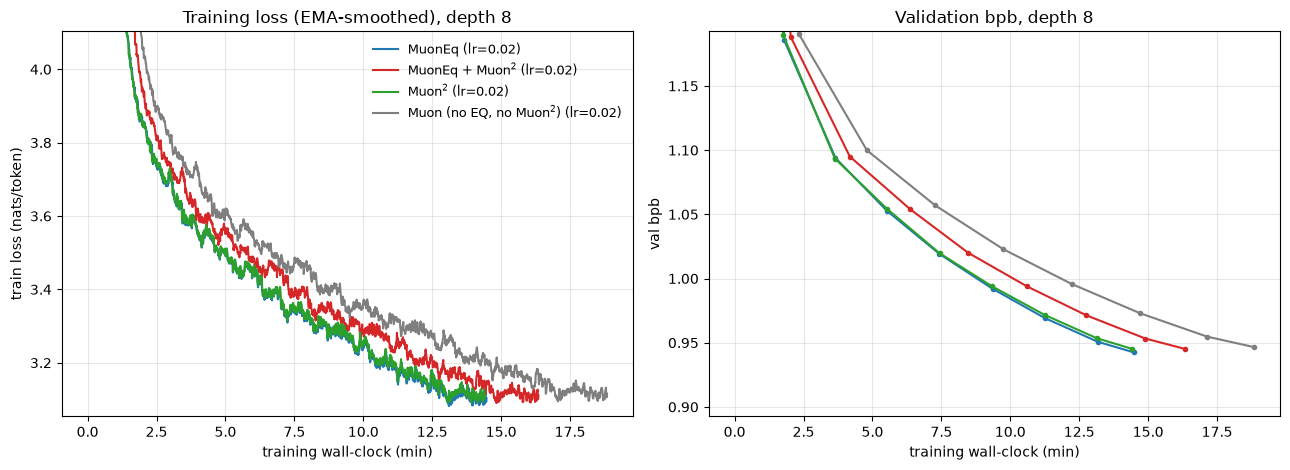

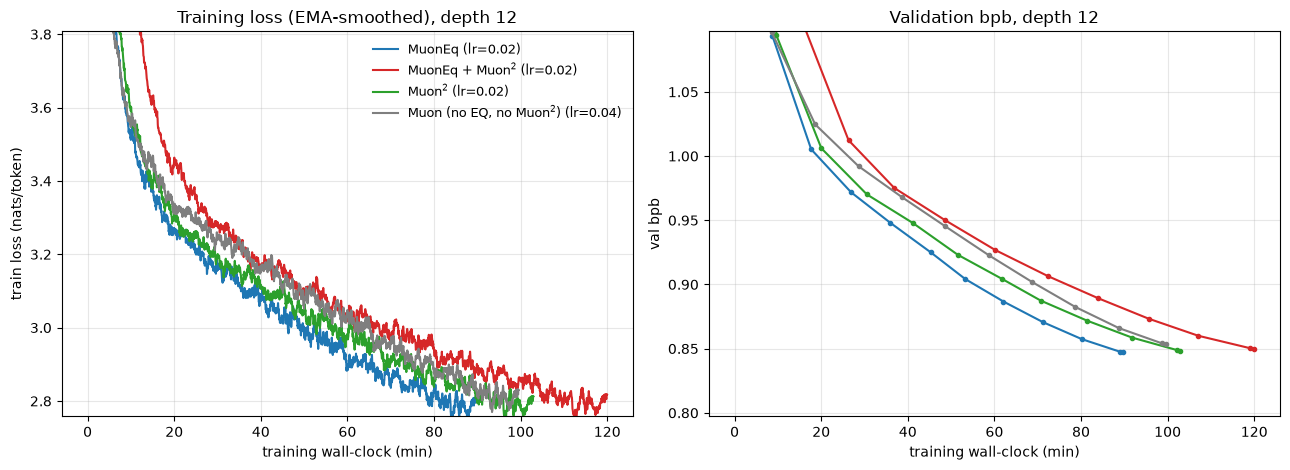

In [4]:
def plot_wallclock(depth):
    vs = [v for v in LABELS if (depth, v) in chosen]
    if not vs:
        return
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
    for v in vs:
        lr = chosen[(depth, v)]
        r = runs[(depth, v, lr)]
        label = f"{LABELS[v]} (lr={lr:g})"
        axes[0].plot(r["train"]["time_min"], r["train"]["loss"], color=COLORS[v], lw=1.5, label=label)
        axes[1].plot(r["val"]["time_min"], r["val"]["val_bpb"], color=COLORS[v], lw=1.5, marker="o", ms=3, label=label)
        if SHOW_ALL_LRS:
            for (d2, v2, lr2), r2 in runs.items():
                if d2 == depth and v2 == v and lr2 != lr and r2["finished"]:
                    axes[0].plot(r2["train"]["time_min"], r2["train"]["loss"], color=COLORS[v], lw=0.6, alpha=0.25)
                    axes[1].plot(r2["val"]["time_min"], r2["val"]["val_bpb"], color=COLORS[v], lw=0.6, alpha=0.25)

    # zoom the y-axes onto the interesting part (drop the initial high-loss transient)
    fl = min(runs[(depth, v, chosen[(depth, v)])]["train"]["loss"].iloc[-1] for v in vs)
    fb = min(runs[(depth, v, chosen[(depth, v)])]["val"]["val_bpb"].iloc[-1] for v in vs)
    axes[0].set_ylim(fl - 0.05, fl + LOSS_ZOOM)
    axes[1].set_ylim(fb - 0.05, fb + BPB_ZOOM)

    axes[0].set_title(f"Training loss (EMA-smoothed), depth {depth}")
    axes[0].set_ylabel("train loss (nats/token)")
    axes[1].set_title(f"Validation bpb, depth {depth}")
    axes[1].set_ylabel("val bpb")
    for ax in axes:
        ax.set_xlabel("training wall-clock (min)")
        ax.grid(alpha=0.3)
    axes[0].legend(frameon=False, fontsize=9)
    plt.tight_layout()
    savefig(fig, f"d{depth}_loss_val_vs_wallclock")
    plt.show()

for depth in avail:
    plot_wallclock(depth)

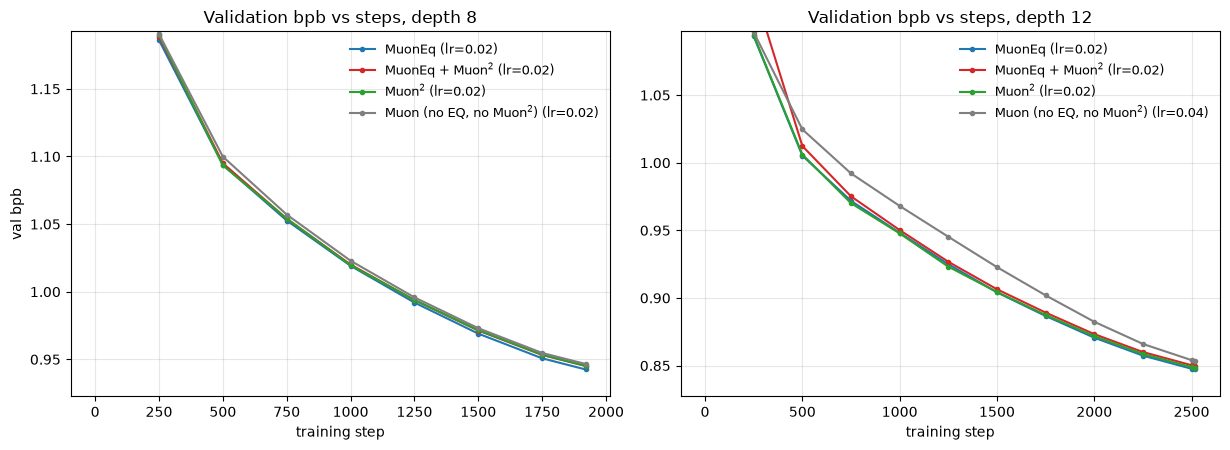

In [5]:
# Validation bpb vs training steps, one panel per depth (each variant at its chosen LR)
if avail:
    fig, axes = plt.subplots(1, len(avail), figsize=(6.2 * len(avail), 4.6), squeeze=False)
    for ax, depth in zip(axes[0], avail):
        vs = [v for v in LABELS if (depth, v) in chosen]
        for v in vs:
            lr = chosen[(depth, v)]
            val = runs[(depth, v, lr)]["val"]
            ax.plot(val["step"], val["val_bpb"], color=COLORS[v], lw=1.5, marker="o", ms=3, label=f"{LABELS[v]} (lr={lr:g})")
        if vs:
            fb = min(runs[(depth, v, chosen[(depth, v)])]["val"]["val_bpb"].iloc[-1] for v in vs)
            ax.set_ylim(fb - 0.02, fb + BPB_ZOOM)
        ax.set_title(f"Validation bpb vs steps, depth {depth}")
        ax.set_xlabel("training step")
        ax.grid(alpha=0.3)
        ax.legend(frameon=False, fontsize=9)
    axes[0][0].set_ylabel("val bpb")
    plt.tight_layout()
    savefig(fig, "val_bpb_vs_steps")
    plt.show()

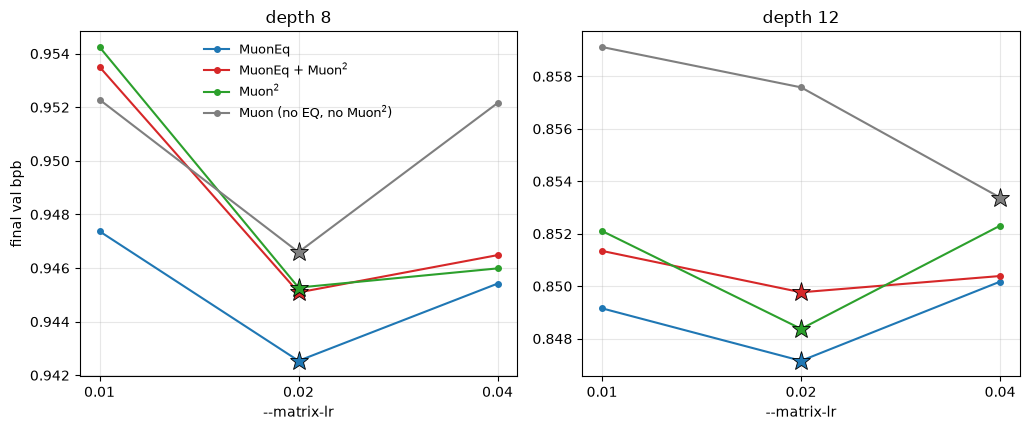

lr               0.01    0.02    0.04
depth variant                        
8     base     0.9523  0.9466  0.9522
      eq       0.9474  0.9425  0.9454
      eq_m2    0.9535  0.9451  0.9465
      m2       0.9542  0.9453  0.9460
12    base     0.8591  0.8576  0.8534
      eq       0.8492  0.8472  0.8502
      eq_m2    0.8513  0.8498  0.8504
      m2       0.8521  0.8484  0.8523

In [6]:
# Final val bpb vs matrix LR, one panel per depth (star = best LR for that variant)
fin = summary[summary.finished]
if fin.empty:
    print("no finished runs yet")
else:
    fig, axes = plt.subplots(1, len(avail), figsize=(5.2 * len(avail), 4.4), squeeze=False)
    for ax, depth in zip(axes[0], avail):
        for v in LABELS:
            s = fin[(fin.depth == depth) & (fin.variant == v)].sort_values("lr")
            if s.empty:
                continue
            ax.plot(s.lr, s.final_val_bpb, color=COLORS[v], marker="o", ms=4, lw=1.5, label=LABELS[v])
            b = s.loc[s.final_val_bpb.idxmin()]
            ax.plot([b.lr], [b.final_val_bpb], color=COLORS[v], marker="*", ms=14, mec="k", mew=0.6)
        lrs = sorted(fin[fin.depth == depth].lr.unique())
        ax.set_xscale("log")
        ax.set_xticks(lrs)
        ax.set_xticklabels([f"{x:g}" for x in lrs])
        ax.minorticks_off()
        ax.set_title(f"depth {depth}")
        ax.set_xlabel("--matrix-lr")
        ax.grid(alpha=0.3)
    axes[0][0].set_ylabel("final val bpb")
    axes[0][0].legend(frameon=False, fontsize=9)
    plt.tight_layout()
    savefig(fig, "val_bpb_vs_lr")
    plt.show()

    # compact table of the same numbers: rows = (depth, variant), columns = LR
    lr_pivot = fin.pivot_table(index=["depth", "variant"], columns="lr", values="final_val_bpb").round(4)
    savetable(lr_pivot, "val_bpb_vs_lr")
    display(lr_pivot)

## Time-to-target

For each depth, the **target is a constant: the worst (highest) final value among the compared variants**, each at its selected LR, so every variant reaches it by the end of its run. We report the first step and wall-clock minute at which each variant reaches the target (linear interpolation between logged points; validation bpb is only logged every `--eval-every` steps, the smoothed train loss every step).

**Speedup** follows the Muon+ paper convention: `T_ref / T_variant - 1`, in %, separately for steps and wall-clock, with `REFERENCE` as the baseline (falls back to the worst variant if `REFERENCE` isn't available at that depth). Positive = faster than the reference. Tokens = steps × the total batch size parsed from the log (NaN if that line isn't found; batch size is identical across variants within a depth).

In [7]:
REFERENCE = "base"   # baseline for the speedup column
TARGET_METRICS = {"val_bpb": "val bpb", "loss": "train loss (EMA)"}

def metric_series(r, metric):
    d = r["val"] if metric == "val_bpb" else r["train"]
    return d["step"].to_numpy(), d["time_min"].to_numpy(), d[metric].to_numpy()

def first_crossing(steps, times, y, target):
    """First (step, minute) at which y <= target, linearly interpolated; NaN if never reached."""
    idx = np.flatnonzero(y <= target)
    if len(idx) == 0:
        return np.nan, np.nan
    i = idx[0]
    if i == 0:
        return steps[0], times[0]
    f = (y[i - 1] - target) / (y[i - 1] - y[i])
    return steps[i - 1] + f * (steps[i] - steps[i - 1]), times[i - 1] + f * (times[i] - times[i - 1])

rows = []
for depth in avail:
    vs = [v for v in LABELS if (depth, v) in chosen]
    if len(vs) < 2:
        continue
    for metric, mname in TARGET_METRICS.items():
        finals = {v: metric_series(runs[(depth, v, chosen[(depth, v)])], metric)[2][-1] for v in vs}
        worst = max(finals, key=finals.get)
        target = finals[worst]
        res = {}
        for v in vs:
            r = runs[(depth, v, chosen[(depth, v)])]
            st, tm = first_crossing(*metric_series(r, metric), target)
            res[v] = dict(steps=st, minutes=tm, tokens_M=st * r["batch_tokens"] / 1e6)
        ref = REFERENCE if REFERENCE in res else worst
        for v in vs:
            rows.append(dict(
                depth=depth, metric=mname, target=target, target_set_by=worst, reference=ref,
                variant=v, lr=chosen[(depth, v)], final=finals[v],
                steps_to_target=res[v]["steps"], tokens_M=res[v]["tokens_M"], minutes_to_target=res[v]["minutes"],
                speedup_steps_pct=(res[ref]["steps"] / res[v]["steps"] - 1) * 100,
                speedup_time_pct=(res[ref]["minutes"] / res[v]["minutes"] - 1) * 100,
            ))

ttt = pd.DataFrame(rows)
if ttt.empty:
    print("need at least two finished variants at a depth")
else:
    ttt = ttt.round({"target": 4, "final": 4, "steps_to_target": 0, "tokens_M": 1, "minutes_to_target": 2,
                     "speedup_steps_pct": 1, "speedup_time_pct": 1})
    savetable(ttt, "time_to_target", index=False)
    display(ttt.set_index(["depth", "metric", "variant"]))

target target_set_by reference    lr   final  \
depth metric           variant                                                 
8     val bpb          eq       0.9466          base      base  0.02  0.9425   
                       eq_m2    0.9466          base      base  0.02  0.9451   
                       m2       0.9466          base      base  0.02  0.9453   
                       base     0.9466          base      base  0.02  0.9466   
      train loss (EMA) eq       3.1159          base      base  0.02  3.1035   
                       eq_m2    3.1159          base      base  0.02  3.1115   
                       m2       3.1159          base      base  0.02  3.1124   
                       base     3.1159          base      base  0.02  3.1159   
12    val bpb          eq       0.8534          base      base  0.02  0.8472   
                       eq_m2    0.8534          base      base  0.02  0.8498   
                       m2       0.8534          base      base  0.02  0.8484   
                       base     0.8534          base      base  0.04  0.8534   
      train loss (EMA) eq       2.8302          base      base  0.02  2.8079   
                       eq_m2    2.8302          base      base  0.02  2.8179   
                       m2       2.8302          base      base  0.02  2.8129   
                       base     2.8302          base      base  0.04  2.8302   

                                steps_to_target  tokens_M  minutes_to_target  \
depth metric           variant                                                 
8     val bpb          eq                1836.0     481.4              13.83   
                       eq_m2             1889.0     495.1              16.08   
                       m2                1893.0     496.2              14.21   
                       base              1920.0     503.3              18.84   
      train loss (EMA) eq                1693.0     443.9              12.74   
                       eq_m2             1694.0     444.0              14.42   
                       m2                1694.0     444.0              12.71   
                       base              1694.0     444.1              16.62   
12    val bpb          eq                2353.0    1233.6              83.81   
                       eq_m2             2421.0    1269.1             115.30   
                       m2                2384.0    1250.1              97.36   
                       base              2520.0    1321.2              99.54   
      train loss (EMA) eq                2036.0    1067.5              72.52   
                       eq_m2             2152.0    1128.0             102.63   
                       m2                2037.0    1067.7              82.86   
                       base              2207.0    1157.1              87.02   

                                speedup_steps_pct  speedup_time_pct  
depth metric           variant                                       
8     val bpb          eq                     4.6              36.2  
                       eq_m2                  1.7              17.1  
                       m2                     1.4              32.6  
                       base                   0.0               0.0  
      train loss (EMA) eq                     0.0              30.4  
                       eq_m2                  0.0              15.3  
                       m2                     0.0              30.8  
                       base                   0.0               0.0  
12    val bpb          eq                     7.1              18.8  
                       eq_m2                  4.1             -13.7  
                       m2                     5.7               2.2  
                       base                   0.0               0.0  
      train loss (EMA) eq                     8.4              20.0  
                       eq_m2                  2.6             -15.2  
                       m2     